In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [5]:
df = pd.read_csv("hotels.csv")

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
df.shape

(119390, 32)

In [8]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [9]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [11]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [12]:
df.describe(include="object")

/var/folders/nn/4xmjnlzn5xb_rfzm978_df_h0000gn/T/ipykernel_44380/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [13]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [14]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

print(missing_percentage)

company                           94.306893
agent                             13.686238
country                            0.408744
children                           0.003350
reserved_room_type                 0.000000
assigned_room_type                 0.000000
booking_changes                    0.000000
deposit_type                       0.000000
hotel                              0.000000
previous_cancellations             0.000000
days_in_waiting_list               0.000000
customer_type                      0.000000
adr                                0.000000
required_car_parking_spaces        0.000000
total_of_special_requests          0.000000
reservation_status                 0.000000
previous_bookings_not_canceled     0.000000
is_repeated_guest                  0.000000
is_canceled                        0.000000
distribution_channel               0.000000
market_segment                     0.000000
meal                               0.000000
babies                          

In [15]:
summary = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique()})
display(summary)
print('Duplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)

,dtype,missing,unique
hotel,str,0,2
is_canceled,int64,0,2
lead_time,int64,0,479
arrival_date_year,int64,0,3
arrival_date_month,str,0,12
arrival_date_week_number,int64,0,53
arrival_date_day_of_month,int64,0,31
stays_in_weekend_nights,int64,0,17
stays_in_week_nights,int64,0,35
adults,int64,0,14


Duplicate rows: 31994


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [16]:
df["country"] = df["country"].fillna("Unknown")

In [17]:
df["company"] = df["company"].fillna(0)
df["agent"] = df["agent"].fillna(0)

In [18]:
df.dropna(inplace=True)

In [19]:
df["children"] = df["children"].fillna(
    df["children"].median()
)

In [20]:
df.duplicated().sum()

np.int64(31994)

is_canceled
0    0.629605
1    0.370395
Name: proportion, dtype: float64


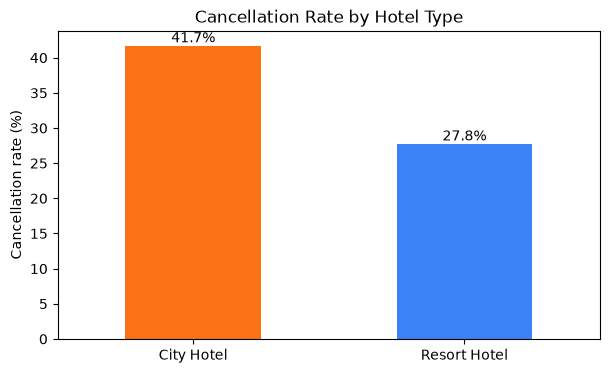

In [21]:
print(df['is_canceled'].value_counts(normalize=True).rename('proportion'))
hotel_rates = df.groupby('hotel')['is_canceled'].mean().mul(100)
ax = hotel_rates.plot(kind='bar', color=['#F97316','#3B82F6'], figsize=(7,4), rot=0)
ax.set(title='Cancellation Rate by Hotel Type', ylabel='Cancellation rate (%)', xlabel='')
ax.bar_label(ax.containers[0], fmt='%.1f%%'); plt.show()

In [22]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [23]:
df["reservation_status_date"] = pd.to_datetime(
    df["reservation_status_date"],
    errors="coerce"
)

In [24]:
df["reservation_status_date"].dtype

dtype('<M8[us]')

In [25]:
df["reservation_year"] = (
    df["reservation_status_date"].dt.year
)

In [26]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,reservation_year
count,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,...,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386.000000,119386,119386.00000
mean,0.370395,104.014801,2016.156593,27.165003,15.798553,0.927605,2.500310,1.856390,0.103890,0.007949,...,0.137102,0.221131,74.830633,10.775518,2.321227,101.833541,0.062520,0.571340,2016-07-30 00:42:11.512907,2016.09378
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000,2014-10-17 00:00:00,2014.00000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,7.000000,0.000000,0.000000,69.290000,0.000000,0.000000,2016-02-02 00:00:00,2016.00000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,9.000000,0.000000,0.000000,94.590000,0.000000,0.000000,2016-08-07 00:00:00,2016.00000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,152.000000,0.000000,0.000000,126.000000,0.000000,1.000000,2017-02-08 00:00:00,2017.00000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,...,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000,2017-09-14 00:00:00,2017.00000
std,0.482913,106.863286,0.707456,13.605334,8.780783,0.998618,1.908289,0.579261,0.398561,0.097438,...,1.497462,0.652315,107.142996,53.944751,17.595011,50.534664,0.245295,0.792798,NaN,0.71529


In [27]:
df[df["adr"] < 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,reservation_year
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,273.0,0.0,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15,2017


In [28]:
df[
    (df["adults"] == 0) &
    (df["children"] == 0) &
    (df["babies"] == 0)
]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,reservation_year
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,0.0,174.0,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06,2015
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,0.0,174.0,0,Transient,0.00,0,0,Check-Out,2015-10-12,2015
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,38.0,0.0,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23,2015
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,308.0,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04,2016
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,308.0,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05,2016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,...,7.0,0.0,0,Transient,100.80,0,0,Check-Out,2017-06-30,2017
115091,City Hotel,0,1,2017,June,26,30,0,1,0,...,0.0,0.0,0,Transient,0.00,1,1,Check-Out,2017-07-01,2017
116251,City Hotel,0,44,2017,July,28,15,1,1,0,...,425.0,0.0,0,Transient,73.80,0,0,Check-Out,2017-07-17,2017
116534,City Hotel,0,2,2017,July,28,15,2,5,0,...,9.0,0.0,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22,2017


In [29]:
df[
    (df["stays_in_weekend_nights"] == 0) &
    (df["stays_in_week_nights"] == 0)
]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,reservation_year
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,240.0,0.0,0,Transient,0.0,0,2,Check-Out,2015-07-06,2015
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,250.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-06,2015
196,Resort Hotel,0,8,2015,July,28,7,0,0,2,...,0.0,0.0,0,Transient,0.0,0,1,Check-Out,2015-07-07,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115483,City Hotel,0,15,2017,July,27,6,0,0,1,...,14.0,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-07-06,2017
117701,City Hotel,0,0,2017,August,32,8,0,0,2,...,262.0,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-08,2017
118029,City Hotel,0,0,2017,August,33,14,0,0,2,...,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-14,2017
118631,City Hotel,0,78,2017,August,34,23,0,0,1,...,98.0,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-08-23,2017


In [39]:
df = df.drop_duplicates()

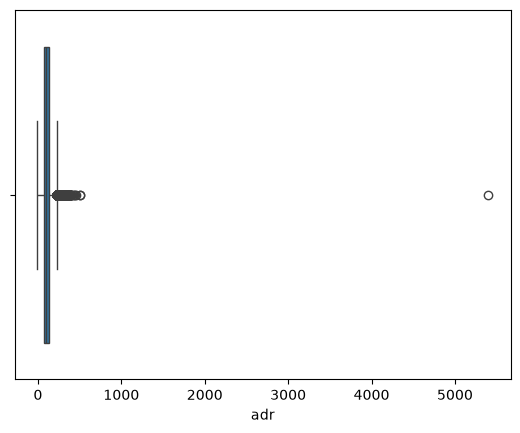

In [40]:
sns.boxplot(x=df["adr"])
plt.show()

In [41]:
import data
df['arrival_date'] = data.arrival_date(df)
train = df[df["arrival_date"] < "2016-07-01"]

<Axes: xlabel='adr', ylabel='arrival_date'>

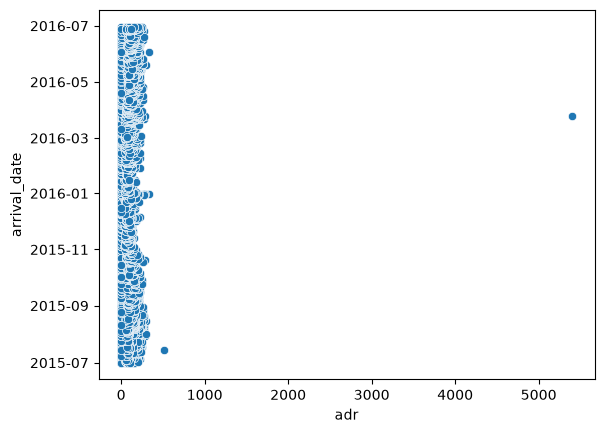

In [42]:
sns.scatterplot(x="adr", y="arrival_date", data=train)

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df[
    (df["adults"] == 0) &
    (df["children"] == 0) &
    (df["babies"] == 0)
]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,reservation_year,arrival_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,174.0,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06,2015,2015-10-06
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,174.0,0,Transient,0.00,0,0,Check-Out,2015-10-12,2015,2015-10-12
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,0.0,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23,2015,2015-11-20
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04,2016,2015-12-30
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05,2016,2015-12-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,...,0.0,0,Transient,100.80,0,0,Check-Out,2017-06-30,2017,2017-06-27
115091,City Hotel,0,1,2017,June,26,30,0,1,0,...,0.0,0,Transient,0.00,1,1,Check-Out,2017-07-01,2017,2017-06-30
116251,City Hotel,0,44,2017,July,28,15,1,1,0,...,0.0,0,Transient,73.80,0,0,Check-Out,2017-07-17,2017,2017-07-15
116534,City Hotel,0,2,2017,July,28,15,2,5,0,...,0.0,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22,2017,2017-07-15


In [45]:
df[
    (df["stays_in_weekend_nights"] == 0) &
    (df["stays_in_week_nights"] == 0)
]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,reservation_year,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015,2015-07-01
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,0.0,0,Transient,0.0,0,2,Check-Out,2015-07-06,2015,2015-07-06
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-06,2015,2015-07-06
196,Resort Hotel,0,8,2015,July,28,7,0,0,2,...,0.0,0,Transient,0.0,0,1,Check-Out,2015-07-07,2015,2015-07-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115483,City Hotel,0,15,2017,July,27,6,0,0,1,...,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-07-06,2017,2017-07-06
117701,City Hotel,0,0,2017,August,32,8,0,0,2,...,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-08,2017,2017-08-08
118029,City Hotel,0,0,2017,August,33,14,0,0,2,...,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-14,2017,2017-08-14
118631,City Hotel,0,78,2017,August,34,23,0,0,1,...,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-08-23,2017,2017-08-23


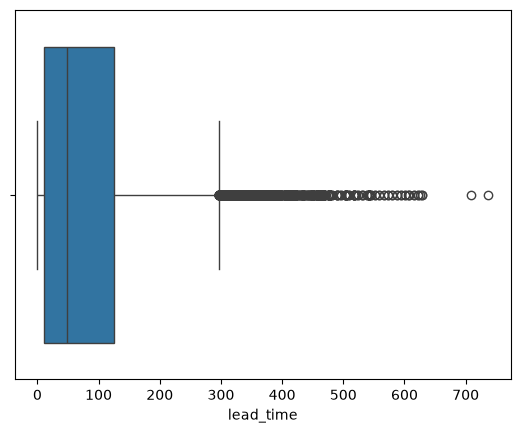

In [46]:
sns.boxplot(x=df["lead_time"])
plt.show()

In [47]:
Q1 = df["adr"].quantile(0.25)
Q3 = df["adr"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["adr"] < lower_limit) |
    (df["adr"] > upper_limit)
]

print("Outliers:", len(outliers))

Outliers: 2490


In [48]:
df["hotel"].unique()

<ArrowStringArray>
['Resort Hotel', 'City Hotel']
Length: 2, dtype: str

In [49]:
df["meal"].unique()

df["market_segment"].unique()

df["customer_type"].unique()

<ArrowStringArray>
['Transient', 'Contract', 'Transient-Party', 'Group']
Length: 4, dtype: str

In [50]:
cat_cols = df.select_dtypes(
    include="object"
).columns

for col in cat_cols:
    df[col] = df[col].str.strip()

/var/folders/nn/4xmjnlzn5xb_rfzm978_df_h0000gn/T/ipykernel_44380/3077400625.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(


In [51]:
df["hotel"] = df["hotel"].str.title()

In [52]:
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
    errors="coerce"
)

In [53]:
df["nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

In [54]:
df["total_guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

In [55]:
df["estimated_stay_revenue"] = (
    df["adr"] * df["nights"]
)

In [56]:
y = df["is_canceled"]

In [57]:
df["is_canceled"].value_counts()

is_canceled
0    63371
1    24021
Name: count, dtype: int64

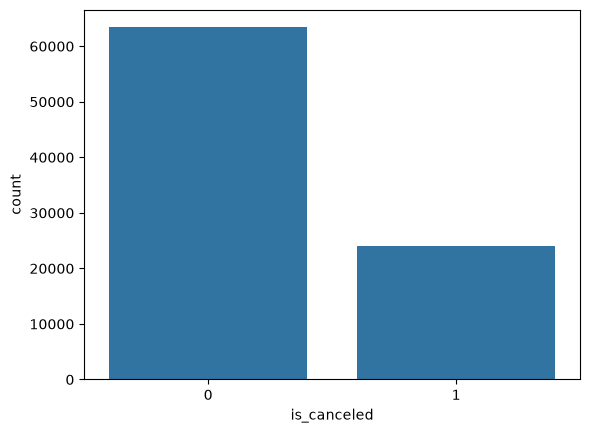

In [58]:
sns.countplot(data=df, x="is_canceled")
plt.show()

In [59]:
# Dataset dimensions
print(df.shape)

# Missing values
print(df.isnull().sum())

# Duplicate rows
print(df.duplicated().sum())

# Data types
print(df.dtypes)

# Statistical summary
print(df.describe())

(87392, 37)
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr             

In [60]:
assert df["lead_time"].ge(0).all()

assert df["stays_in_weekend_nights"].ge(0).all()

assert df["stays_in_week_nights"].ge(0).all()

assert df["is_canceled"].isin([0, 1]).all()

In [61]:
df.to_csv("hotels_cleaned.csv", index=False)

In [62]:
cleaned_df = pd.read_csv("hotels_cleaned.csv")

cleaned_df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,reservation_year,arrival_date,nights,total_guests,estimated_stay_revenue
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,0,0,Check-Out,2015-07-01,2015,2015-07-01,0,2.0,0.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,0,0,Check-Out,2015-07-01,2015,2015-07-01,0,2.0,0.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,75.0,0,0,Check-Out,2015-07-02,2015,2015-07-01,1,1.0,75.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,75.0,0,0,Check-Out,2015-07-02,2015,2015-07-01,1,1.0,75.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,98.0,0,1,Check-Out,2015-07-03,2015,2015-07-01,2,2.0,196.0
